SANTIAGO DIE MOREJÓN - 23/03/2026 - IA - Entregable 1 - Adicional 2 - Análisis Estadístico de Clasificadores

# Notebook 5 - Adicional 2: Análisis Estadístico para Comparar Clasificadores

En el notebook de comparativa y en el adicional 1 determinamos que Random Forest es el mejor modelo basándonos en el accuracy. Sin embargo, como vimos en la Práctica 6, que un clasificador sea mejor en un split concreto puede deberse a la casualidad.

En este notebook vamos a aplicar la metodología estadística vista en clase para confirmar si las diferencias entre modelos son estadísticamente significativas.

## 1. Carga de datos y librerías

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
sns.set()
%config InlineBackend.figure_format = 'svg'
import warnings; warnings.simplefilter('ignore')

In [2]:
!wget -q DATA_URL -O train.csv
!wget -q DATA_URL  -O test.csv

In [3]:
traindf = pd.read_csv('train.csv')
testdf  = pd.read_csv('test.csv')

## 2. Preparación de los datos

Usamos los 5 descriptores originales y preparamos versiones escaladas y sin escalar, ya que algunos modelos (KNN, MLP) necesitan `StandardScaler` mientras que los basados en árboles (RF, DT) no.

In [4]:
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import cross_val_score, StratifiedKFold

cols = ['SL', 'EEG', 'BP', 'HR', 'CIRCULATION']

X = traindf[cols].values
y = traindf['ACTIVITY'].values

scaler = StandardScaler()
X_sc = scaler.fit_transform(X)

## 3. Validación Cruzada (10-fold)

Evaluamos los 4 modelos no lineales del notebook de optimización con sus mejores hiperparámetros mediante validación cruzada estratificada de 10 folds. Esto nos da 10 medidas de accuracy por modelo, que usaremos para el análisis estadístico.

In [5]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.neural_network import MLPClassifier

Ejecutamos la validación cruzada con 10 folds estratificados.

In [6]:
cv = StratifiedKFold(n_splits=10, shuffle=True, random_state=42)

Definimos los modelos con los mejores hiperparámetros encontrados en el Adicional 1.

In [7]:
scores_rf = cross_val_score(
    RandomForestClassifier(n_estimators=500, max_depth=20, min_samples_split=5, max_features=0.5, min_samples_leaf=1, random_state=42),
    X, y, cv=cv, scoring='accuracy')
print(f'Random Forest   media={scores_rf.mean():.4f}  std={scores_rf.std():.4f}')

Random Forest   media=0.7595  std=0.0081


In [8]:
scores_dt = cross_val_score(
    DecisionTreeClassifier(random_state=42),
    X, y, cv=cv, scoring='accuracy')
print(f'Árbol Decisión  media={scores_dt.mean():.4f}  std={scores_dt.std():.4f}')

Árbol Decisión  media=0.6810  std=0.0105


In [9]:
scores_knn = cross_val_score(
    KNeighborsClassifier(n_neighbors=5, weights='uniform', p=2),
    X_sc, y, cv=cv, scoring='accuracy')
print(f'KNN             media={scores_knn.mean():.4f}  std={scores_knn.std():.4f}')

KNN             media=0.6416  std=0.0155


In [10]:
scores_mlp = cross_val_score(
    MLPClassifier(hidden_layer_sizes=(300,300), learning_rate_init=0.01, max_iter=1000, random_state=42),
    X_sc, y, cv=cv, scoring='accuracy')
print(f'MLP             media={scores_mlp.mean():.4f}  std={scores_mlp.std():.4f}')

MLP             media=0.6598  std=0.0128


### 3.1 Visualización de los resultados de CV

Representamos la distribución de accuracy de cada modelo con boxplots.

In [11]:
resultados_cv = {
    'Random Forest': scores_rf.mean(),
    'Árbol Decisión': scores_dt.mean(),
    'KNN': scores_knn.mean(),
    'MLP': scores_mlp.mean()
}
cv_df = pd.DataFrame({
    'Random Forest': scores_rf,
    'Árbol Decisión': scores_dt,
    'KNN': scores_knn,
    'MLP': scores_mlp
})
res = pd.Series(resultados_cv).sort_values(ascending=False)

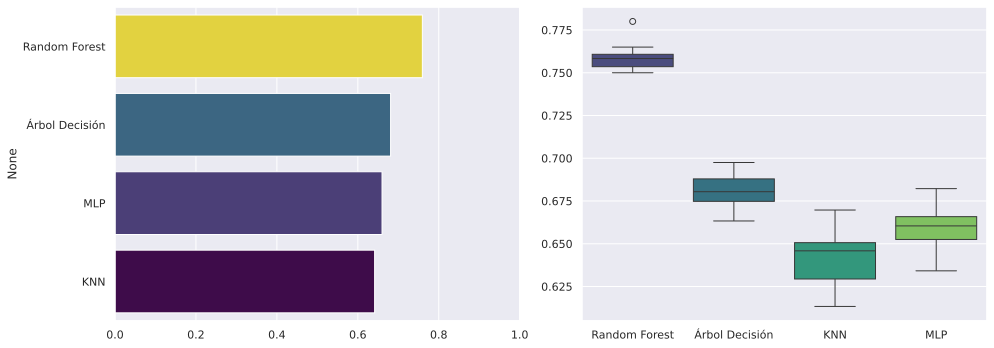

In [12]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
sns.barplot(x=res.values, hue=res.values, y=res.index, ax=axes[0], palette='viridis', legend=False)
axes[0].set_xlim(0, 1)
sns.boxplot(data=cv_df, palette='viridis', ax=axes[1])
plt.tight_layout()

## 4. Evaluando los algoritmos en el conjunto de test

Para evaluar los distintos algoritmos vamos a utilizar la función `classification_report` de la librería sklearn. Para ello hacemos la predicción con respecto al conjunto de test y mostramos los resultados.

In [20]:
from sklearn.model_selection import train_test_split

In [21]:
(trainData, testData, trainLabels, testLabels) = train_test_split(X, y, test_size=0.25, random_state=42)
scaler_split = StandardScaler()
trainData_sc = scaler_split.fit_transform(trainData)
testData_sc  = scaler_split.transform(testData)

In [22]:
from sklearn.metrics import classification_report

**Random Forest**

In [23]:
modelRF = RandomForestClassifier(n_estimators=500, max_depth=20, min_samples_split=5, max_features=0.5, min_samples_leaf=1, random_state=42)
modelRF.fit(trainData, trainLabels)
print("EVALUACIÓN EN CONJUNTO DE TEST USANDO RANDOM FOREST")
predictionsRF = modelRF.predict(testData)
print(classification_report(testLabels, predictionsRF))

EVALUACIÓN EN CONJUNTO DE TEST USANDO RANDOM FOREST
              precision    recall  f1-score   support

           0       0.96      0.95      0.95       875
           1       0.78      0.79      0.79        95
           2       0.70      0.73      0.71       433
           3       0.64      0.73      0.68       624
           4       0.67      0.61      0.64       662
           5       0.67      0.56      0.61       311

    accuracy                           0.75      3000
   macro avg       0.74      0.73      0.73      3000
weighted avg       0.76      0.75      0.75      3000



**Árbol de Decisión**

In [24]:
modelDT = DecisionTreeClassifier(random_state=42)
modelDT.fit(trainData, trainLabels)
print("EVALUACIÓN EN CONJUNTO DE TEST USANDO ÁRBOL DE DECISIÓN")
predictionsDT = modelDT.predict(testData)
print(classification_report(testLabels, predictionsDT))

EVALUACIÓN EN CONJUNTO DE TEST USANDO ÁRBOL DE DECISIÓN
              precision    recall  f1-score   support

           0       0.94      0.81      0.87       875
           1       0.75      0.80      0.77        95
           2       0.64      0.67      0.66       433
           3       0.58      0.62      0.60       624
           4       0.58      0.59      0.58       662
           5       0.52      0.56      0.54       311

    accuracy                           0.68      3000
   macro avg       0.67      0.68      0.67      3000
weighted avg       0.69      0.68      0.68      3000



**KNN**

In [25]:
modelKNN = KNeighborsClassifier(n_neighbors=5, weights='uniform', p=2)
modelKNN.fit(trainData_sc, trainLabels)
print("EVALUACIÓN EN CONJUNTO DE TEST USANDO KNN")
predictionsKNN = modelKNN.predict(testData_sc)
print(classification_report(testLabels, predictionsKNN))

EVALUACIÓN EN CONJUNTO DE TEST USANDO KNN
              precision    recall  f1-score   support

           0       0.87      0.70      0.78       875
           1       0.71      0.75      0.73        95
           2       0.56      0.74      0.64       433
           3       0.52      0.64      0.58       624
           4       0.59      0.55      0.57       662
           5       0.55      0.43      0.48       311

    accuracy                           0.63      3000
   macro avg       0.63      0.64      0.63      3000
weighted avg       0.65      0.63      0.64      3000



**MLP**

In [26]:
modelMLP = MLPClassifier(hidden_layer_sizes=(300,300), learning_rate_init=0.01, max_iter=1000, random_state=42)
modelMLP.fit(trainData_sc, trainLabels)
print("EVALUACIÓN EN CONJUNTO DE TEST USANDO MLP")
predictionsMLP = modelMLP.predict(testData_sc)
print(classification_report(testLabels, predictionsMLP))

EVALUACIÓN EN CONJUNTO DE TEST USANDO MLP
              precision    recall  f1-score   support

           0       0.91      0.78      0.84       875
           1       0.63      0.82      0.72        95
           2       0.53      0.72      0.61       433
           3       0.57      0.56      0.57       624
           4       0.56      0.55      0.55       662
           5       0.55      0.49      0.52       311

    accuracy                           0.65      3000
   macro avg       0.63      0.65      0.63      3000
weighted avg       0.66      0.65      0.65      3000



| Modelo | Accuracy | Precision | Recall | F1-score |
|-|-|-|-|-|
| Random Forest | 0.75 | 0.76 | 0.75 | 0.75 |
| Árbol Decisión | 0.68 | 0.69 | 0.68 | 0.68 |
| MLP | 0.65 | 0.66 | 0.65 | 0.65 |
| KNN | 0.63 | 0.65 | 0.63 | 0.64 |

Random Forest es el mejor en todas las métricas, seguido de Árbol de Decisión. MLP supera ligeramente a KNN pese a que ambos usan datos escalados.

## 5. Análisis con compare_methods

Utilizamos la función `compare_methods` de la librería `StatisticalAnalysis` que usamos en la Práctica 6 para realizar el análisis completo de forma automática.

In [13]:
!pip install -q StatisticalAnalysis

  Preparing metadata (setup.py) ... done


In [33]:
from StatisticalAnalysis import compare_methods
from scipy.stats import randint as sp_randint

In [27]:
clfRF  = RandomForestClassifier(n_estimators=500, max_depth=20, min_samples_split=5, max_features=0.5, min_samples_leaf=1, random_state=42)
clfDT  = DecisionTreeClassifier(random_state=42)
clfKNN = KNeighborsClassifier(n_neighbors=5, weights='uniform', p=2)
clfMLP = MLPClassifier(hidden_layer_sizes=(300,300), learning_rate_init=0.01, max_iter=1000, random_state=42)

In [16]:
listAlgorithms = [clfRF, clfDT, clfKNN, clfMLP]

In [28]:
listParams     = [None, None, None, None]

In [29]:
listNames      = ['RandomForest', 'ArbolDecision', 'KNN', 'MLP']

temp.csv
['RandomForest' 'ArbolDecision' 'KNN' 'MLP']
Report
**********************************************************
Mean and std
**********************************************************
RandomForest: 0.758813 (0.010914)
ArbolDecision: 0.679889 (0.009917)
KNN: 0.610967 (0.011252)
MLP: 0.306277 (0.037875)
**********************************************************
Statistical tests
**********************************************************
----------------------------------------------------------
Checking parametric conditions 
----------------------------------------------------------
Checking independence 
Ok
Checking normality using Shapiro-Wilk's test for normality, alpha=0.05
W: 0.814597, p:0.000014
The null hypothesis (normality) is rejected
Checking heteroscedasticity using Levene's test, alpha=0.05
W: 8.356004, p:0.000240
The null hypothesis (heteroscedasticity) is rejected
Conditions for a parametric test are not fulfilled, applying a non-parametric test
------------------

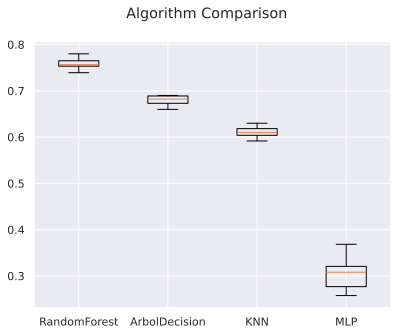

In [30]:
compare_methods(X, y, listAlgorithms, listParams, listNames, metric='accuracy')

Se ha aplicado un test no paramétrico, al no cumplirse ni la normalidad ni la homocedasticidad:
- *"The null hypothesis (normality) is rejected"* (Shapiro-Wilk: W=0.8146, p=0.000014)
- *"The null hypothesis (heteroscedasticity) is rejected"* (Levene: W=8.356, p=0.000240)

*"Conditions for a parametric test are not fulfilled, applying a non-parametric test"*. Para que se use un test paramétrico se tienen que cumplir todas las condiciones.

El modelo ganador es RandomForest con una media de 0.7588 y desviación típica de 0.0109, obteniendo un ranking de 4 en el test de Quade.

Hay diferencias significativas con todos los modelos:

- RandomForest vs MLP (mean: 0.3063): Cohen's d=15.40, Large → diferencia significativa
- RandomForest vs KNN (mean: 0.6110): Cohen's d=12.65, Large → diferencia significativa
- RandomForest vs ArbolDecision (mean: 0.6799): Cohen's d=7.18, Large → diferencia significativa

MLP y KNN obtienen rendimiento inferior al del notebook de comparativa porque `compare_methods` no permite escalar los datos internamente , y ambos modelos necesitan datos escalados para converger correctamente.

El análisis confirma que Random Forest es significativamente superior al resto.

## 6. Matriz de Confusión del Mejor Modelo

Para analizar en detalle dónde acierta y falla nuestro mejor modelo (Random Forest), calculamos la matriz de confusión con validación cruzada.

In [34]:
from sklearn.model_selection import cross_val_predict
from sklearn.metrics import confusion_matrix

In [35]:
rf = RandomForestClassifier(n_estimators=500, max_depth=20, min_samples_split=5, max_features=0.5, min_samples_leaf=1, random_state=42)
y_pred_cv = cross_val_predict(rf, X, y, cv=cv)
print('Classification Report — Random Forest (10-fold CV):')
print(classification_report(y, y_pred_cv, digits=4))

Classification Report — Random Forest (10-fold CV):
              precision    recall  f1-score   support

           0     0.9519    0.9647    0.9583      3344
           1     0.7923    0.7817    0.7870       371
           2     0.7199    0.7393    0.7295      1849
           3     0.6496    0.7097    0.6783      2625
           4     0.6617    0.6411    0.6512      2569
           5     0.7287    0.5802    0.6460      1241

    accuracy                         0.7595     11999
   macro avg     0.7507    0.7361    0.7417     11999
weighted avg     0.7599    0.7595    0.7584     11999



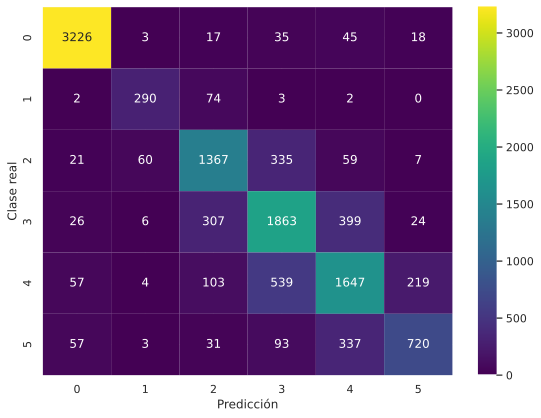

In [36]:
cm = confusion_matrix(y, y_pred_cv)

plt.figure(figsize=(8, 6))
sns.heatmap(cm, annot=True, fmt='d', cmap='viridis', xticklabels=range(6), yticklabels=range(6))
plt.xlabel('Predicción')
plt.ylabel('Clase real')
plt.tight_layout()
plt.show()

La diagonal principal nos dice las instancias correctamente clasificadas.

- La clase 0 es la mejor clasificada (96.5% recall) y tiene valores extremos en la mayoría de descriptores, lo que facilita su identificación.
- La clase 1 tiene buen recall (78.2%) pese a ser la más minoritaria del dataset, con solo 371 instancias.
- Las clases 3, 4 y 5 son las que mas se confunden entre sí. La clase 3 se confunde 399 con 4 , la clase 4 539 veces con 3 , y la clase 5 337 veces con 4. Esto concuerda con el fuerte solapamiento observado en el pairplot y en t-SNE en el notebok 2.
- La Clase 2 se confunde principalmente con 3,para ser precisos 335 errores veces. Esto también los vimos en la visualización.

## 7. Análisis adicional del mejor modelo

### 7.1 Importancia de descriptores

Utilizando el atributo `feature_importances_` del Random Forest podemos ver la relevancia de cada descriptor, igual que en la Práctica 6 Adicional 1.

In [37]:
rf_final = RandomForestClassifier(n_estimators=500, max_depth=20, min_samples_split=5, max_features=0.5, min_samples_leaf=1, random_state=42)
rf_final.fit(X, y)

RandomForestClassifier(max_depth=20, max_features=0.5, min_samples_split=5,
                       n_estimators=500, random_state=42)

In [38]:
relevancias = rf_final.feature_importances_
indices = np.argsort(relevancias)[::-1]
etiquetas = np.array(cols)

In [39]:
for f in range(len(cols)):
    print("%2d) %-*s %f" % (f+1, 15, etiquetas[indices[f]], relevancias[indices[f]]))

 1) SL              0.246222
 2) EEG             0.210241
 3) HR              0.191636
 4) CIRCULATION     0.183665
 5) BP              0.168236


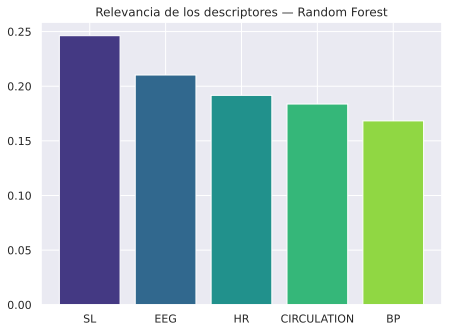

In [41]:
plt.title('Relevancia de los descriptores — Random Forest')
plt.bar(range(len(cols)), relevancias[indices], color=sns.color_palette('viridis', len(cols)), align='center')
plt.xticks(range(len(cols)), etiquetas[indices])
plt.tight_layout()
plt.show()

El descriptor más relevante es SL (0.246), seguido de EEG (0.210), HR (0.192), CIRCULATION (0.184) y BP (0.168). Las importancias están bastante repartidas entre los 5 descriptores.

Lo que sorprende es que EEG aparezca como segundo más importante para Random Forest, cuando en el análisis lo clasificamos como inútil. Esto se debe a que Random Forest puede capturar interacciones no lineales sutiles que no son visibles en boxplots o correlaciones simples. También que SL y CIRCULATION, que son altamente redundantes (r=0.98), se reparten la importancia entre ambos en lugar de concentrarla en uno solo.

### 7.2 Curva de aprendizaje

La curva de aprendizaje nos permite visualizar si el modelo sufre de subajuste o sobreajuste, igual que en la Práctica 6 Adicional 2.

In [42]:
!wget https://raw.githubusercontent.com/IA1819/Code/master/plot_curves.py -O plot_curves.py

--2026-03-24 03:39:15--  https://raw.githubusercontent.com/IA1819/Code/master/plot_curves.py
Resolving raw.githubusercontent.com (raw.githubusercontent.com)... 185.199.111.133, 185.199.110.133, 185.199.109.133, ...
Connecting to raw.githubusercontent.com (raw.githubusercontent.com)|185.199.111.133|:443... connected.
HTTP request sent, awaiting response... 200 OK
Length: 2662 (2.6K) [text/plain]
Saving to: ‘plot_curves.py’

plot_curves.py      100%[===================>]   2.60K  --.-KB/s    in 0s      

2026-03-24 03:39:15 (26.5 MB/s) - ‘plot_curves.py’ saved [2662/2662]



In [43]:
from plot_curves import *

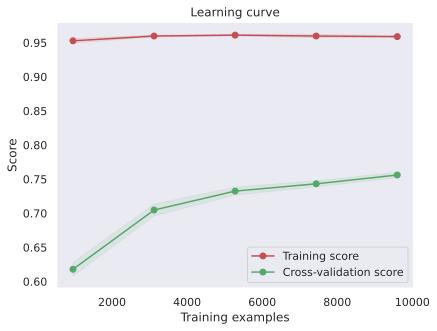

In [44]:
plot_learning_curve(RandomForestClassifier(n_estimators=500, max_depth=20, min_samples_split=5, max_features=0.5, min_samples_leaf=1, random_state=42),X, y)

La curva de aprendizaje muestra:

- Training score alto y estable (~0.96) el modelo aprende muy bien los datos de entrenamiento.
- Cross-validation score sube progresivamente desde 0.60 con pocas instancias hasta 0.76 con todo el dataset.
- Hay un diferencia entre ambas curvas que indica cierto sobreajuste, ya que el modelo rinde mucho mejor en entrenamiento que en validación.
- La curva de CV sigue subiendo al final lo que nos lleva a pensar que más datos podrían mejorar el rendimiento, ya que el modelo aún no se ha estabilizado completamente.

## 8. Conclusión

El análisis estadístico con `compare_methods`, siguiendo la misma metodología de la Práctica 6, confirma que:

* Se ha aplicado un test no paramétrico , ya que no se cumplen ni la normalidad ni la homocedasticidad de las distribuciones de accuracy.

* Random Forest es el mejor modelo de forma estadísticamente significativa, con una media de 0.7588 en 10-fold CV. Las diferencias con MLP y KNN son visibles.

* La matriz de confusión confirma las observaciones del notebook 2. La clase 0 es la más fácil de clasificar (96.5% recall), mientras que las clases 3, 4 y 5 presentan las mayores confusiones entre sí debido al solapamiento en el espacio de descriptores.

* MLP y KNN obtienen rendimiento inferior al del notebook de comparativa porque `compare_methods` no permite escalar los datos internamente, y ambos modelos necesitan datos estandarizados para converger correctamente.

* La importancia de descriptores muestra que los 5 contribuyen de forma bastante equilibrada, siendo SL (0.246) y EEG (0.210) los más relevantes para Random Forest, que nos dice que el modelo captura interacciones no lineales que no son visibles en el análisis exploratorio.

* La curva de aprendizaje revela cierto sobreajuste, pero la curva de validación sigue subiendo, lo que nos dice que más datos podrían mejorar el rendimiento.

El resultado estadístico confirma que Random Forest es el modelo seleccionado para el envío a Kaggle. Finalmente en el ultimo notebook usaremos este para realizar la prediccion